<h1>Pytorch Convolutional Autoencoder</h1>


Importing libraries:

In [1]:
# The MNIST datasets are hosted on yann.lecun.com that has moved under CloudFlare protection
# Run this script to enable the datasets download
# Reference: https://github.com/pytorch/vision/issues/1938
from six.moves import urllib
opener = urllib.request.build_opener()
opener.addheaders = [('User-agent', 'Mozilla/5.0')]
urllib.request.install_opener(opener)

import torch
import numpy as np
from torchvision import datasets
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
%matplotlib inline
import torch.nn as nn
import torch.nn.functional as F

print(torch.__version__)

2.0.1+cu118


Loading datasets and creating dataloaders:

In [ ]:
# convert data to torch.FloatTensor
transform = transforms.ToTensor()

# load the training and test datasets
train_data = datasets.MNIST(root='~/.pytorch/MNIST_data/', train=True, download=True, transform=transform)
test_data = datasets.MNIST(root='~/.pytorch/MNIST_data/', train=False, download=True, transform=transform)

100%|██████████| 9912422/9912422 [00:00<00:00, 99663705.16it/s]


Extracting /root/.pytorch/MNIST_data/MNIST/raw/train-images-idx3-ubyte.gz to /root/.pytorch/MNIST_data/MNIST/raw



100%|██████████| 28881/28881 [00:00<00:00, 78455760.25it/s]

Extracting /root/.pytorch/MNIST_data/MNIST/raw/train-labels-idx1-ubyte.gz to /root/.pytorch/MNIST_data/MNIST/raw




100%|██████████| 1648877/1648877 [00:00<00:00, 28283540.80it/s]


Extracting /root/.pytorch/MNIST_data/MNIST/raw/t10k-images-idx3-ubyte.gz to /root/.pytorch/MNIST_data/MNIST/raw



100%|██████████| 4542/4542 [00:00<00:00, 641065.01it/s]

Extracting /root/.pytorch/MNIST_data/MNIST/raw/t10k-labels-idx1-ubyte.gz to /root/.pytorch/MNIST_data/MNIST/raw



In [ ]:
# Create training and test dataloaders

num_workers = 0
# how many samples per batch to load
batch_size = 20

# prepare data loaders
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, num_workers=num_workers)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, num_workers=num_workers)

print(train_data)
print(test_data)

Dataset MNIST
    Number of datapoints: 60000
    Root location: /root/.pytorch/MNIST_data/
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset MNIST
    Number of datapoints: 10000
    Root location: /root/.pytorch/MNIST_data/
    Split: Test
    StandardTransform
Transform: ToTensor()


Visualize the data


torch.Size([20, 1, 28, 28])


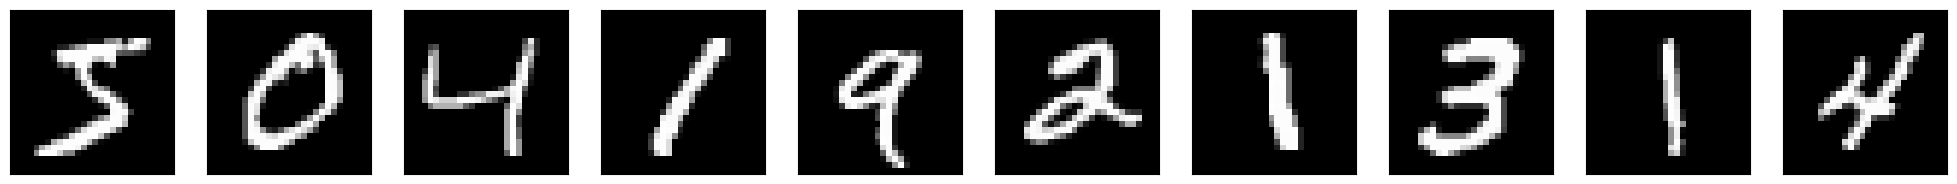

In [ ]:
# obtain one batch of training images
dataiter = iter(train_loader)
images, labels = next(dataiter)
print(images.shape)

n = 10
plt.figure(figsize=(25, 4))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    plt.imshow(np.squeeze(images[i]), cmap='gray')

plt.show()

Building the Encode-Decode network


In [ ]:
class CAE_Encoder(nn.Module):
    def __init__(self):
        super(CAE_Encoder, self).__init__()
        ## encoder layers ##
        # conv layer (depth from 1 --> 16), 3x3 kernels
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        # conv layer (depth from 16 --> 4), 3x3 kernels
        self.conv2 = nn.Conv2d(16, 4, 3, padding=1)
        # pooling layer to reduce x-y dims by two; kernel and stride of 2
        self.pool = nn.MaxPool2d(2, 2)

    def forward(self, x):
        ## encode ##
        # add hidden layers with relu activation function
        # and maxpooling after
        #print('Encoding:', x.shape)
        x = self.conv1(x)
        #print('after conv1:', x.shape)
        x = F.relu(x)
        #print('after relu1:', x.shape)
        x = self.pool(x)
        #print('after max pooling 1:', x.shape)
        # add second hidden layer
        x = self.conv2(x)
        #print('after conv2:', x.shape)
        x = F.relu(x)
        #print('after relu2:', x.shape)
        x = self.pool(x)  # compressed representation
        #print('after max pooling 2:', x.shape)
        return x

enc_model = CAE_Encoder()
print(enc_model)
print(list(enc_model.parameters())[0].size())

CAE_Encoder(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
torch.Size([16, 1, 3, 3])


In [ ]:
class CAE_Decoder(nn.Module):
    def __init__(self):
        super(CAE_Decoder, self).__init__()

        ## decoder layers ##
        ## a kernel of 2 and a stride of 2 will increase the spatial dims by 2
        self.t_conv1 = nn.ConvTranspose2d(4, 16, 2, stride=2)
        self.t_conv2 = nn.ConvTranspose2d(16, 1, 2, stride=2)


    def forward(self, x):

        ## decode ##
        # add transpose conv layers, with relu activation function
        #print('Decoding')
        x = self.t_conv1(x)
        #print('after t_conv 1:', x.shape)
        x = F.relu(x)
        #print('after relu3:', x.shape)
        # output layer (with sigmoid for scaling from 0 to 1)
        x = self.t_conv2(x)
        #print('after t_conv 2:', x.shape)
        x = F.sigmoid(x)
        #print('after sigmoid:', x.shape)
        return x

dec_model = CAE_Decoder()
print(dec_model)
print(list(dec_model.parameters())[0].size())

CAE_Decoder(
  (t_conv1): ConvTranspose2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
  (t_conv2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
)
torch.Size([4, 16, 2, 2])


In [ ]:
class AutoEncoder(nn.Module):
    def __init__(self):
        super(AutoEncoder, self).__init__()

        # generate two NN, for decoder and encoder operations
        self.encoder = CAE_Encoder()
        self.decoder = CAE_Decoder()

        self.train_line = nn.Sequential(self.encoder, self.decoder)

    # forward propagation (encode + decode)
    def forward(self, x):
        return self.train_line(x)

    # encode data to reduced dimensionality form
    def encode(self,x):
        return self.encoder(x)

    # decode reduced dimensionality data
    def decode(self,x):
        return self.decoder(x)


model = AutoEncoder()
print(model)
print(list(model.parameters())[0].size())

AutoEncoder(
  (encoder): CAE_Encoder(
    (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (conv2): Conv2d(16, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): CAE_Decoder(
    (t_conv1): ConvTranspose2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
    (t_conv2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
  )
  (train_line): Sequential(
    (0): CAE_Encoder(
      (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (conv2): Conv2d(16, 4, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): CAE_Decoder(
      (t_conv1): ConvTranspose2d(4, 16, kernel_size=(2, 2), stride=(2, 2))
      (t_conv2): ConvTranspose2d(16, 1, kernel_size=(2, 2), stride=(2, 2))
    )
  )
)
torch.Size([16, 1, 3, 3])


Configure and train the model


In [ ]:
# specify loss function
criterion = nn.MSELoss()

# specify loss function
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [ ]:
# number of epochs to train the model
n_epochs = 30

for epoch in range(1, n_epochs+1):
    # monitor training loss
    train_loss = 0.0

    ###################
    # train the model #
    ###################
    for data in train_loader:
        # _ stands in for labels, here
        # no need to flatten images
        images, _ = data
        # clear the gradients of all optimized variables
        optimizer.zero_grad()
        # forward pass: compute predicted outputs by passing inputs to the model
        outputs = model(images)
        # calculate the loss
        loss = criterion(outputs, images)
        # backward pass: compute gradient of the loss with respect to model parameters
        loss.backward()
        # perform a single optimization step (parameter update)
        optimizer.step()
        # update running training loss
        train_loss += loss.item()*images.size(0)

    # print avg training statistics
    train_loss = train_loss/len(train_loader)
    print('Epoch: {} \tTraining Loss: {:.6f}'.format(epoch,train_loss))

Epoch: 1 	Training Loss: 0.422456
Epoch: 2 	Training Loss: 0.270688
Epoch: 3 	Training Loss: 0.252967
Epoch: 4 	Training Loss: 0.241716
Epoch: 5 	Training Loss: 0.233646
Epoch: 6 	Training Loss: 0.227121
Epoch: 7 	Training Loss: 0.221287
Epoch: 8 	Training Loss: 0.217198
Epoch: 9 	Training Loss: 0.213627
Epoch: 10 	Training Loss: 0.210679
Epoch: 11 	Training Loss: 0.208213
Epoch: 12 	Training Loss: 0.206327
Epoch: 13 	Training Loss: 0.204735
Epoch: 14 	Training Loss: 0.203225
Epoch: 15 	Training Loss: 0.201758
Epoch: 16 	Training Loss: 0.200434
Epoch: 17 	Training Loss: 0.199211
Epoch: 18 	Training Loss: 0.198026
Epoch: 19 	Training Loss: 0.196985
Epoch: 20 	Training Loss: 0.196051
Epoch: 21 	Training Loss: 0.195214
Epoch: 22 	Training Loss: 0.194452
Epoch: 23 	Training Loss: 0.193726
Epoch: 24 	Training Loss: 0.193019
Epoch: 25 	Training Loss: 0.192313
Epoch: 26 	Training Loss: 0.191557
Epoch: 27 	Training Loss: 0.190947
Epoch: 28 	Training Loss: 0.190431
Epoch: 29 	Training Loss: 0.1

Checking out the results:


torch.Size([4, 7, 7])
tensor([[[4.6112, 4.6112, 4.6112, 4.6112, 4.6112, 4.6112, 4.6112],
         [4.6994, 4.7302, 4.3716, 4.7904, 4.7909, 4.7060, 4.6451],
         [4.6089, 4.6608, 4.6953, 4.2129, 3.0773, 4.5134, 4.6581],
         [4.6112, 4.6112, 4.6335, 4.7318, 0.6888, 5.0319, 4.6505],
         [4.6112, 4.6112, 4.6962, 4.1996, 4.9289, 5.0965, 4.6112],
         [4.6112, 4.6720, 4.6835, 2.2000, 5.1143, 4.6518, 4.6112],
         [4.6498, 4.7171, 3.9032, 5.3524, 4.7636, 4.6498, 4.6498]],

        [[0.9858, 0.9858, 0.9858, 0.9858, 0.9858, 0.9858, 0.9858],
         [1.2389, 4.7217, 4.9870, 1.6910, 1.6663, 1.0973, 0.9720],
         [1.1591, 4.0925, 6.5259, 6.8123, 7.3108, 4.8163, 1.2053],
         [0.9858, 1.0595, 1.2360, 1.9559, 7.0569, 3.3364, 1.1049],
         [0.9858, 0.9858, 1.6068, 6.6605, 6.3484, 1.6420, 0.9858],
         [0.9858, 0.9952, 4.1995, 6.9979, 1.8677, 1.1248, 0.9858],
         [0.9858, 1.1619, 5.8783, 6.2038, 1.7830, 0.9858, 0.9858]],

        [[3.4434, 3.4434, 3.4434, 3.

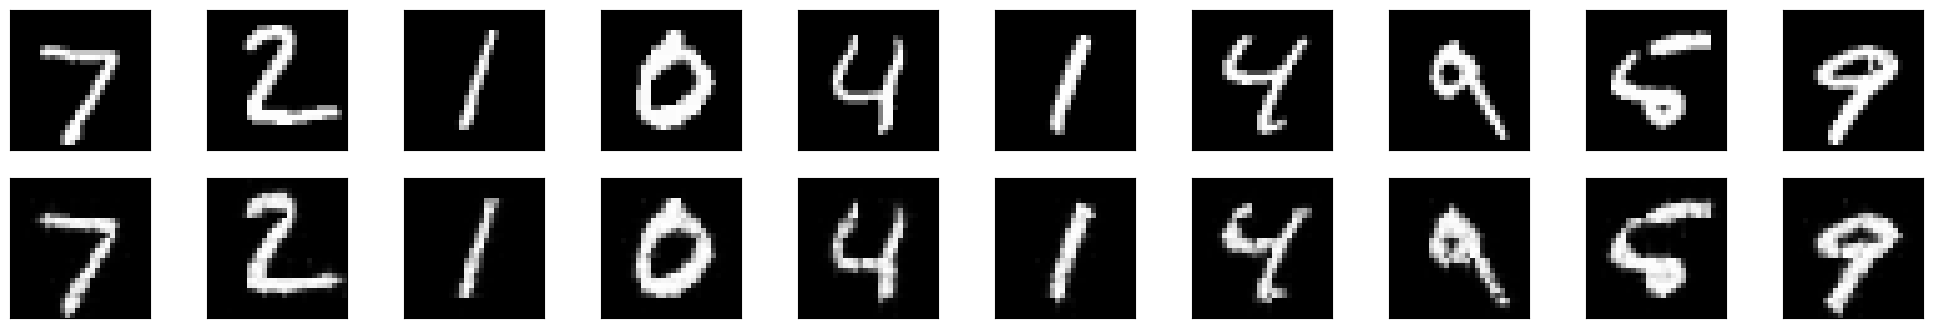

In [ ]:
# obtain one batch of test images
dataiter = iter(test_loader)
images, labels = next(dataiter)

latent = model.encode(images)
print(latent[0].shape)
print(latent[0])

# get sample outputs
output = model.decode(latent)

# execute all encode-decode process instead
#output = model(images)

# prep images for display
images = images.numpy()

# output is resized into a batch of images
output = output.view(batch_size, 1, 28, 28)
# use detach when it's an output that requires_grad
output = output.detach().numpy()

# plot the first ten input images and then reconstructed images
fig, axes = plt.subplots(nrows=2, ncols=10, sharex=True, sharey=True, figsize=(25,4))

# input images on top row, reconstructions on bottom
for images, row in zip([images, output], axes):
    for img, ax in zip(images, row):
        ax.imshow(np.squeeze(img), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)


Saving the Model as Pytorch script, and run it

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
torch.Size([20, 4, 7, 7])
tensor([[[[4.6112, 4.6112, 4.6703,  ..., 4.0655, 4.6112, 4.6112],
          [4.6112, 4.6112, 4.7004,  ..., 5.0567, 4.6754, 4.6112],
          [4.6112, 4.6767, 4.6025,  ..., 5.1369, 4.6136, 4.6112],
          ...,
          [4.6112, 4.7274, 1.9020,  ..., 2.5828, 4.8152, 4.6112],
          [4.6112, 4.7119, 4.5734,  ..., 4.3476, 5.0360, 4.6112],
          [4.6498, 4.6498, 4.6498,  ..., 4.9937, 4.6930, 4.6498]],

         [[0.9858, 0.9858, 0.9858,  ..., 4.4696, 1.1902, 0.9858],
          [0.9858, 0.9858, 1.5877,  ..., 4.5716, 1.2793, 0.9858],
          [0.9858, 0.9858, 4.5572,  ..., 1.5508, 0.9895, 0.9858],
          ...,
          [0.9858, 1.3274, 6.5209,  ..., 5.1857, 1.5429, 0.9858],
          [0.9858, 1.0838, 3.3461,  ..., 5.1633, 1.3793, 0.9858],
          [0.9858, 0.9858, 0.9830,  ..., 1.2836, 1.2196, 0.9858]],

         [[3.4434, 

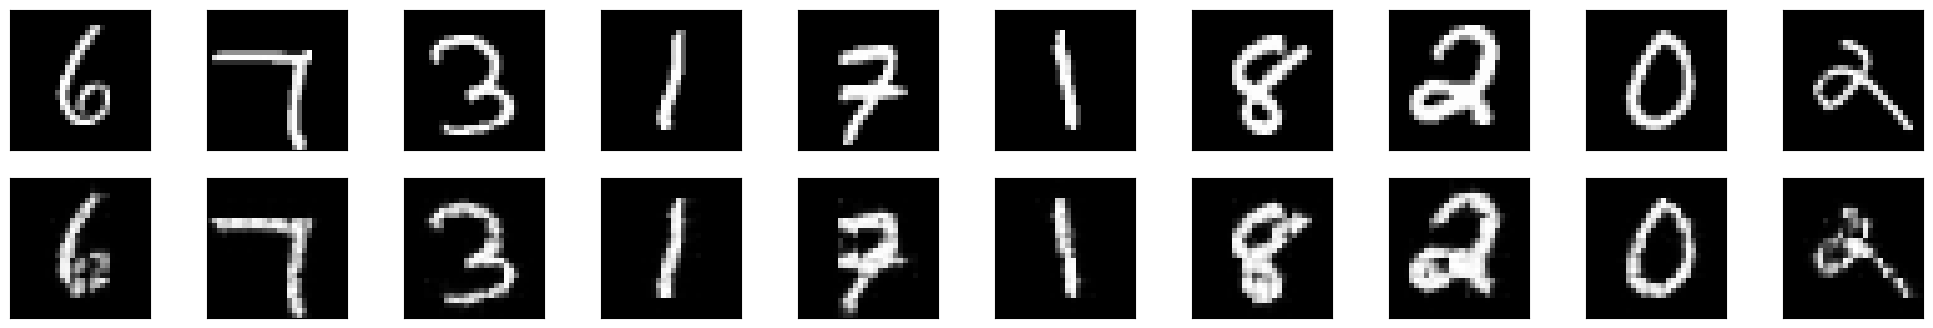

In [ ]:
#Mouting colab with the drive
from google.colab import drive
drive.mount('/content/drive')
base_location = '/content/drive/My Drive/Colab Notebooks/Autoencoder'

#obtain one batch of test images
images, labels = next(dataiter)

#saving the encoder model as a pt script
traced_script = torch.jit.trace(model.encoder, images)
traced_script.save(base_location + '/Pytorch/MNIST_CAE/Encoder_model.pt')

#getting the latent vector through the script
latent_output = traced_script(images)
print(latent_output.shape)
print(latent_output)

#decode the latent vector using the original decoder model
output = model.decode(latent_output)
images = images.numpy()

output = output.view(batch_size, 1, 28, 28)
output = output.detach().numpy()

fig, axes = plt.subplots(nrows=2, ncols=10, sharex=True, sharey=True, figsize=(25,4))

# input images on top row, reconstructions on bottom
for images, row in zip([images, output], axes):
    for img, ax in zip(images, row):
        ax.imshow(np.squeeze(img), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)